# Autocalibration

This is auto-calibration for the DeGeerelva setups.

See how to install mobipy: https://nivanorge.github.io/Mobius2/mobipydocs/mobipy.html#installation

In [1]:
import mobipy
import mobipy.optim as opt
import mobipy.stats as stat

In [2]:
mobipy.allow_logging(False) # Suppress warnings

In [3]:
simple_setup = False

In [4]:
model = '../models/simplyq_arctic.txt'
base_dir = '../data/degeer/'
if simple_setup :
    params = base_dir + 'degeer_simple.dat'
    result_file = base_dir + 'degeer_simple_optimized.dat'
else :
    params = base_dir + 'degeer_quickflow.dat'
    result_file = base_dir + 'degeer_quickflow_optimized.dat'
    
app = mobipy.Model_Application.build_from_model_and_data_file(
    model,
    params
)

optim_start = '2003-1-1'
optim_end   = '2017-12-31'
app.end_date = optim_end  # No reason to run it longer

app.run()

True

In [5]:

# The tuple that identifies an optimized parameter is:
# (module name, symbol/identifier (from the module file), indexes, min value, max value)
par_dict = {
    'temp_lapse' : ('ArcticAtmosphere', 'temp_lapse_rate', [], -0.0098, -0.0028),
    'ddf_snow' : ('ArcticSnow', 'ddf0_melt', [], 1, 5),
    'ddf_ice' : ('SimplyGlacier', 'ddf_ice', [], 3, 12),
    'tc_s' : ('SimplyPermafrostFlow', 'tc_s', ["DeGeerdalen"], 0.1, 2)
}
if not simple_setup :
    par_dict |= {
        'refr' : ('ArcticSnow', 'refr_eff', [], 0, 0.5),
        'liq' : ('ArcticSnow', 'snow_liq', [], 0, 0.4),
        'ald' : ('ArcticSnow', 'ald_max_infiltration', [], 0, 1000)
    }

params, set_params = opt.params_from_dict(app, par_dict)

target = ("Daily mean reach flow", "DeGeerdalen", "Q (m3/s)", ())

get_sim_obs = opt.residual_from_target(target, optim_start, optim_end)

In [6]:
# Run a minimizer to find a single best parameter set

# Extract stats from before the optimization
sim, obs = get_sim_obs(app)
ns_before = stat.nash_sutcliffe(sim, obs)
kg_before = stat.kling_gupta(sim, obs)

# Run the optimizer (This can take several minutes)
res_opt = opt.run_minimizer(app, params, set_params, get_sim_obs)

# Write the optimal parameters to the main app object
set_params(app, res_opt.params)
app.run()

# Extract stats after optimization
sim, obs = get_sim_obs(app)
ns_after = stat.nash_sutcliffe(sim, obs)
kg_after = stat.kling_gupta(sim, obs)

print("Nash-Sutcliffe efficiency: before: %g, after %g" % (ns_before, ns_after))
print("Kling-Gupta efficiency: before: %g, after %g" % (kg_before, kg_after))

Nash-Sutcliffe efficiency: before: 0.742953, after 0.758447
Kling-Gupta efficiency: before: 0.84395, after 0.860582


In [7]:
app.save_data_set(result_file)

In [8]:
# Set up an MCMC run

mc_params = res_opt.params.copy()
# If you just want to run it straight from here without running the optimizer first, just do:
# mc_params = params.copy()

opt.add_wls_params(mc_params, 
                   0.01, 0, 0.05,
                   0.5, 0.01, 1.5)
log_likelihood = opt.ll_from_target(target, optim_start, optim_end)

In [9]:
# Run a full MCMC sampling of the parameter space (can take hours)
burn = 1000
steps = 4000 # TODO: This may be a bit short
walkers = 50
res = opt.run_mcmc(app, mc_params, set_params, log_likelihood, burn=burn, steps=steps, walkers=walkers, progress=True)

# The summary statistics in the LMFIT results object do not account for the burn-in period, so we correct it.
res = opt.update_mcmc_results(res, burn)

100%|██████████| 4000/4000 [14:49:17<00:00, 13.34s/it]  


The chain is shorter than 50 times the integrated autocorrelation time for 9 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 80;
tau: [140.97609609 148.91726021 193.00009072 416.60894999 341.49589603
 346.97508498 314.89059529 442.08826312 361.95638893]


In [14]:
import mobipy.plotting as mplt
import pickle as pkl

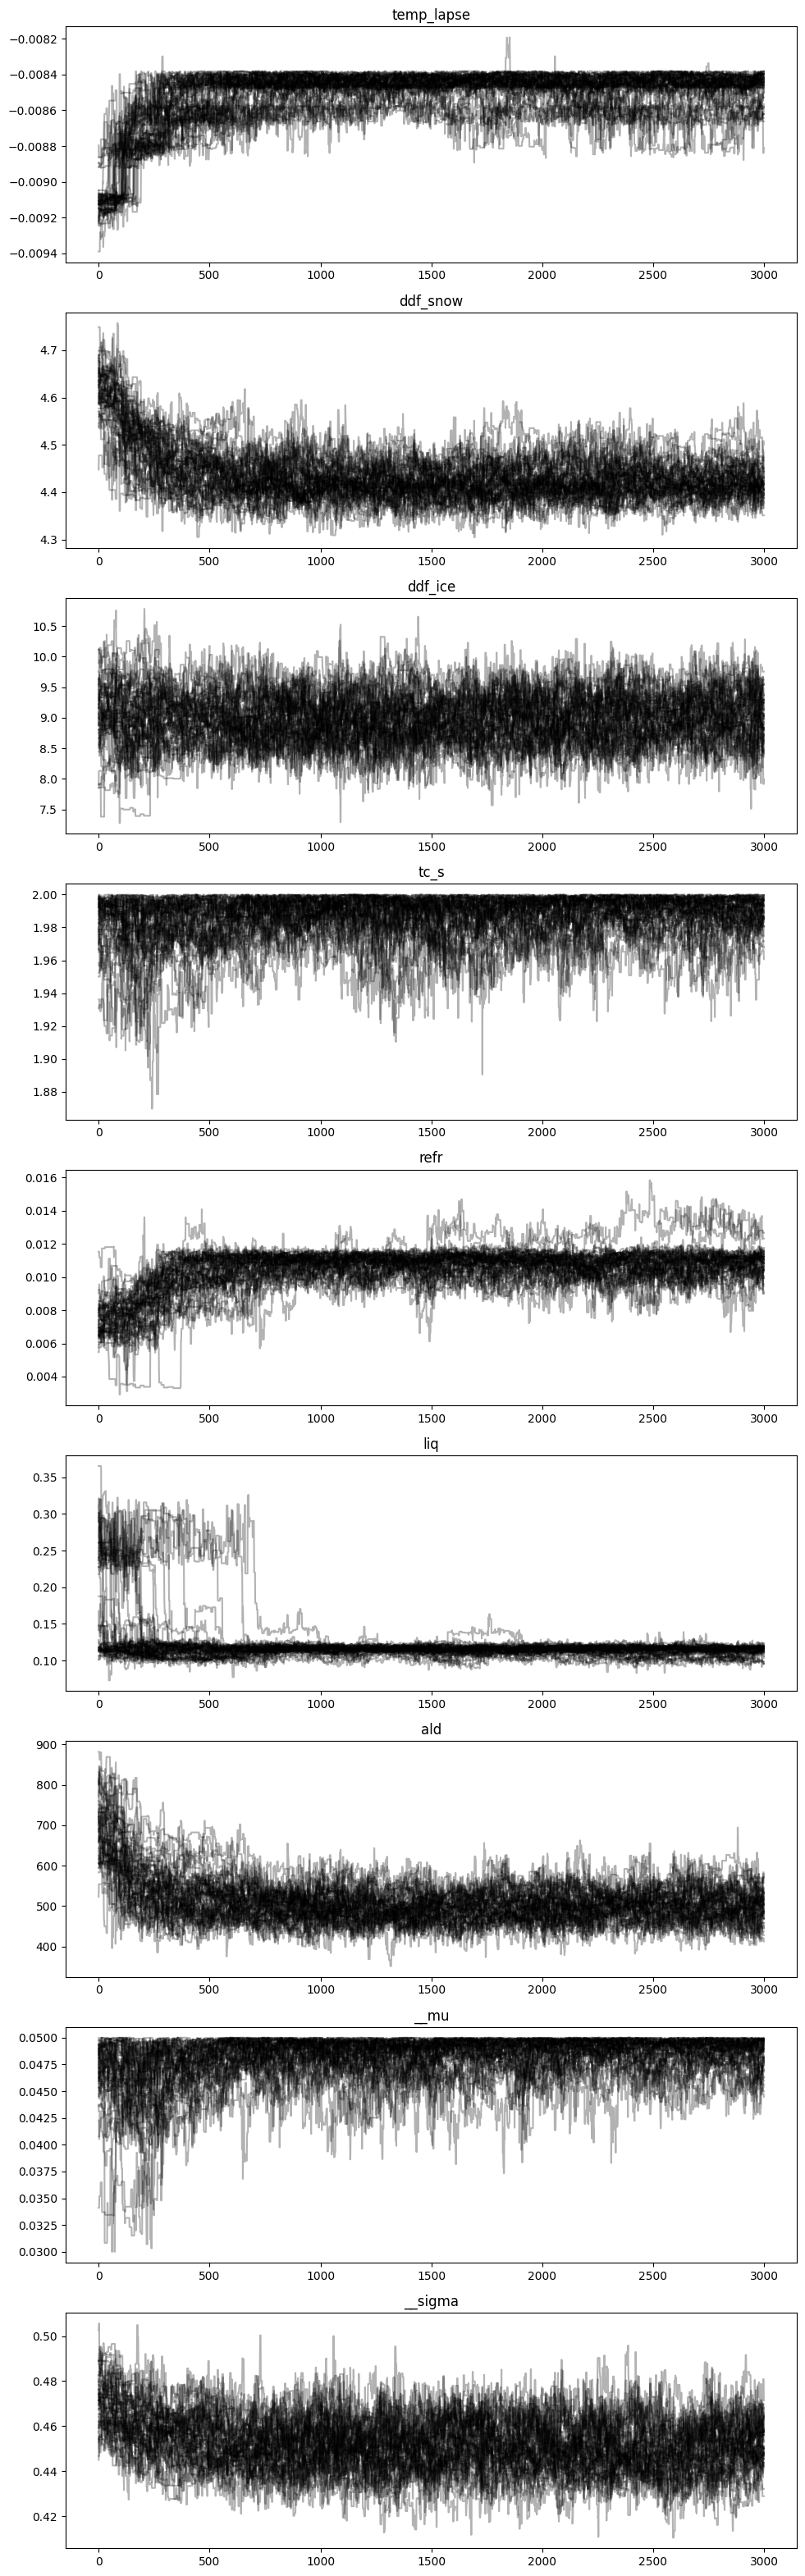

In [12]:
mplt.chain_plot(res)

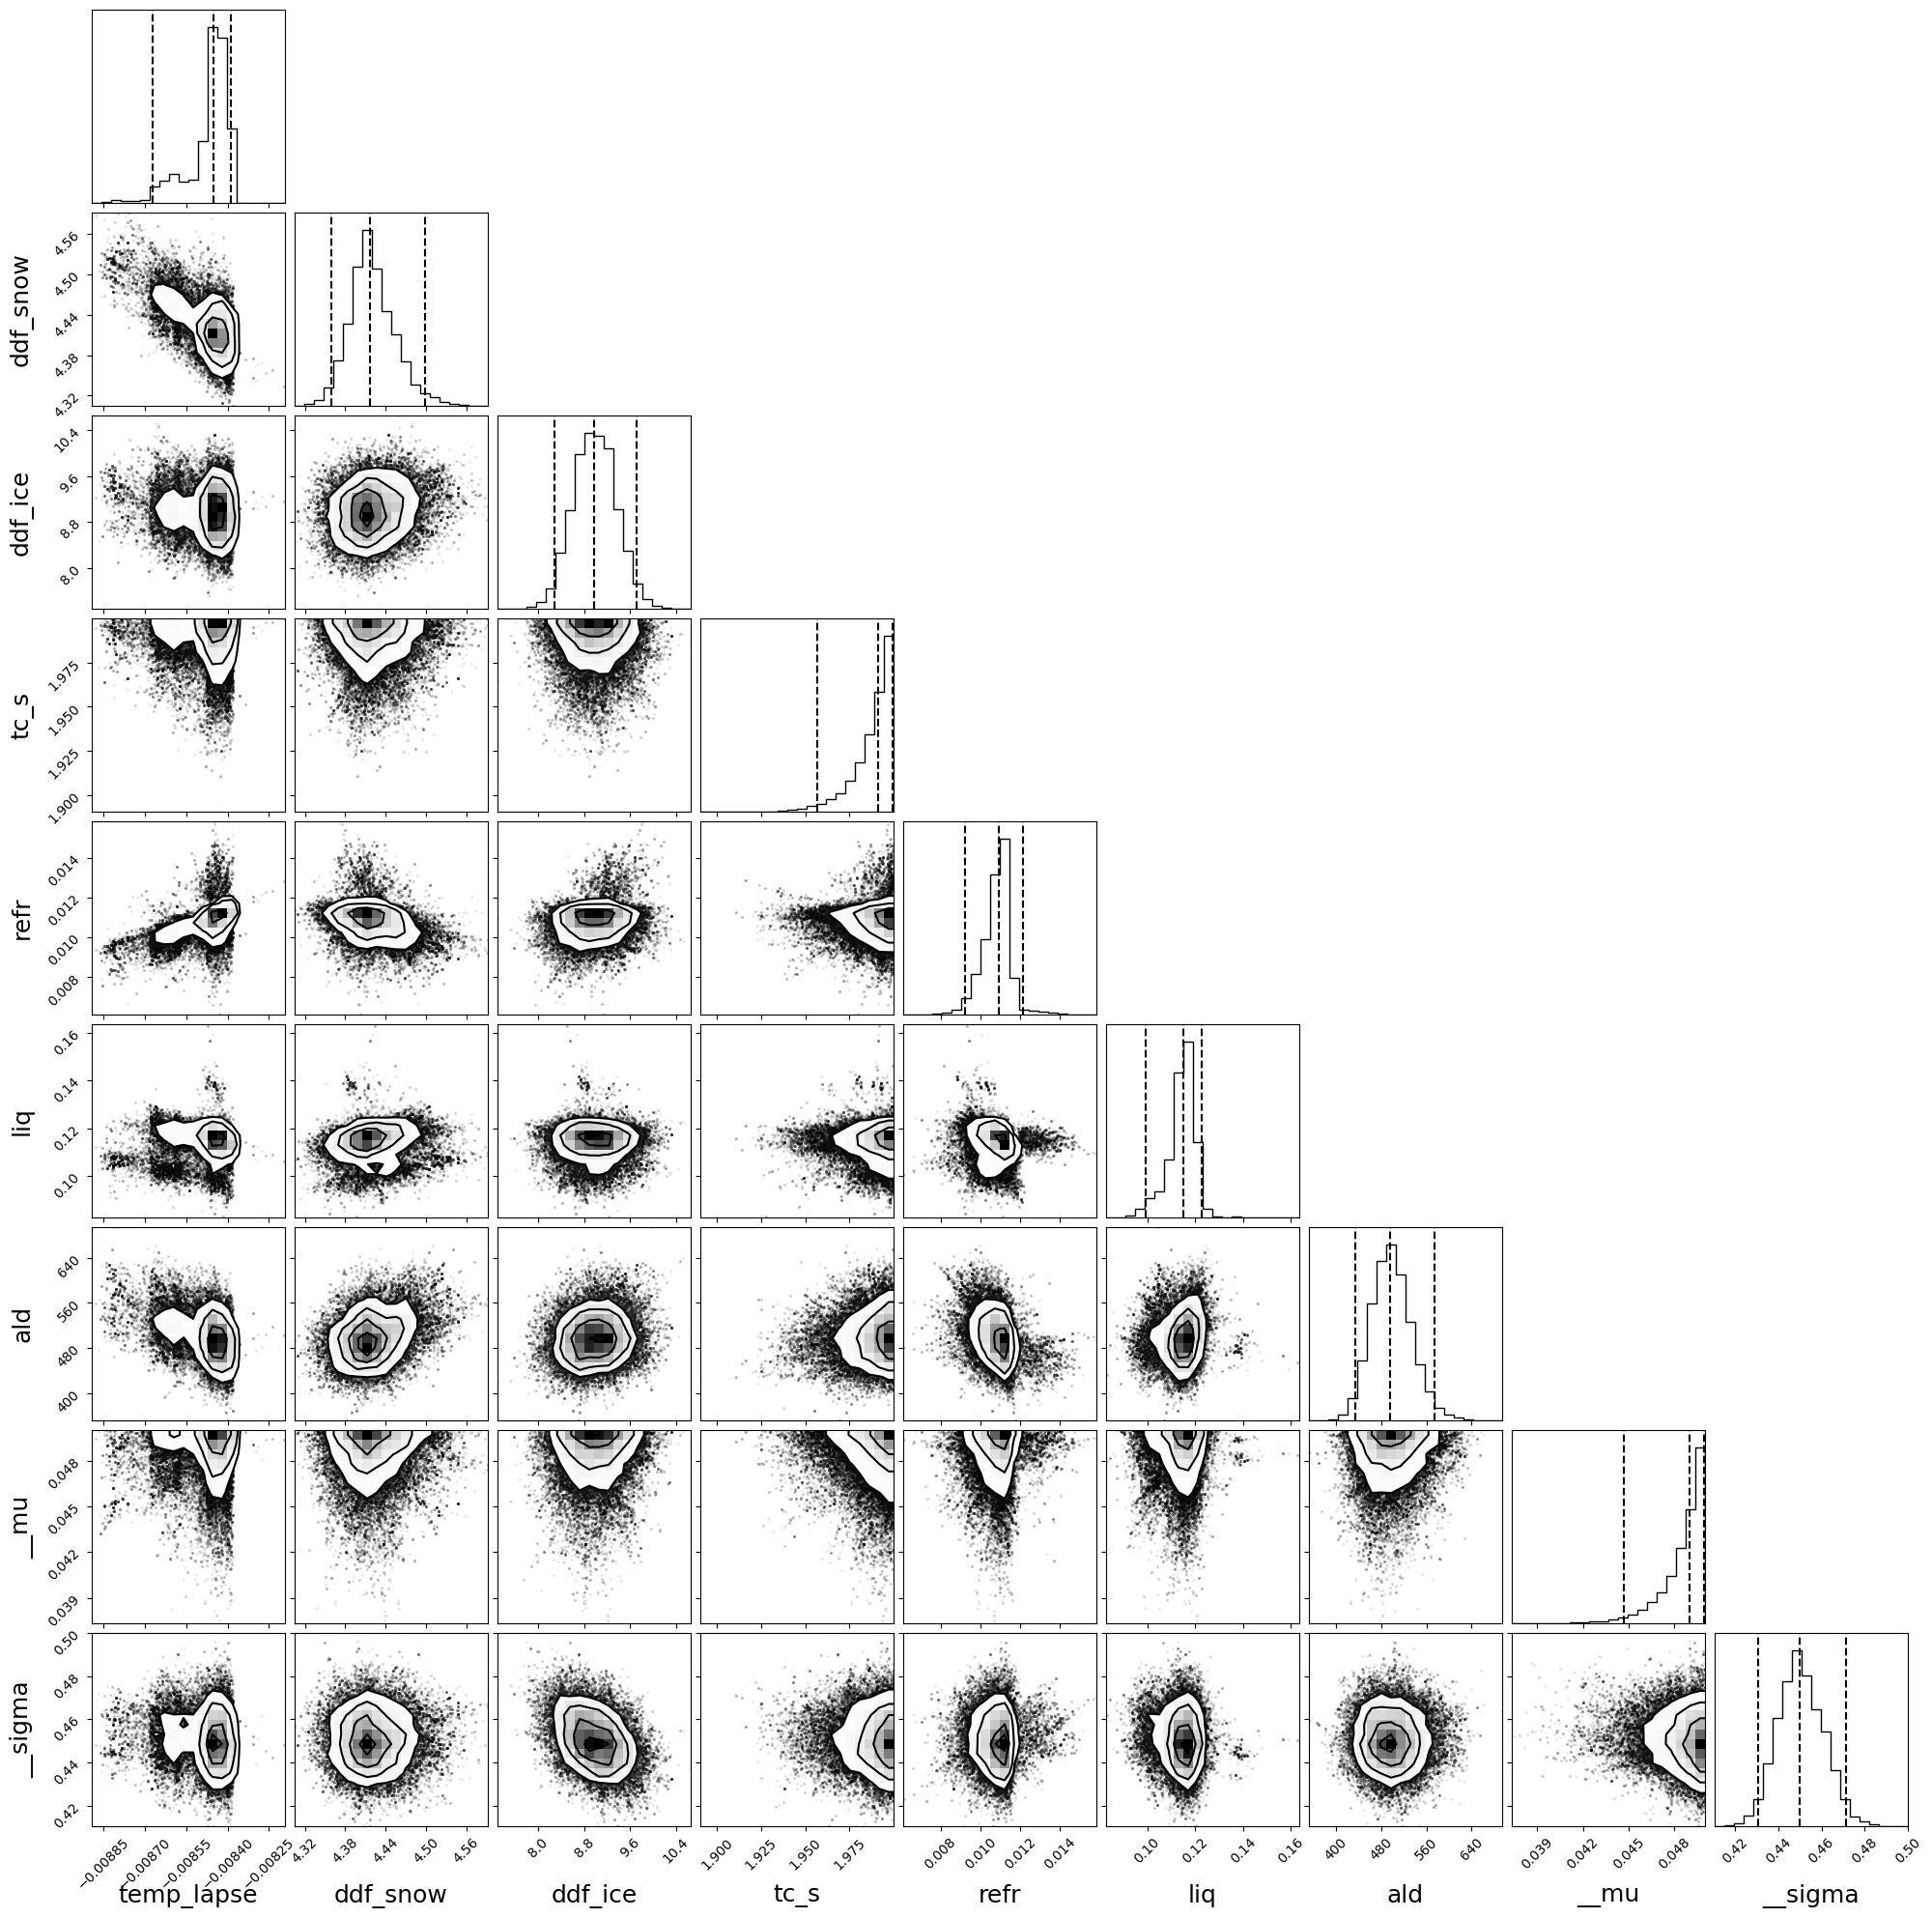

In [13]:
mplt.corner_plot(res, burn)

In [16]:
data_to_save = {
    'res' : res
}
with open("mc_results.pkl", "wb") as file:
    pkl.dump(data_to_save, file)